# 7 · 2-D flexural backstripping along the Viking Graben transect

**What.** Treat the lithosphere as an elastic plate that bends under the sediment and water load, instead of local (Airy) isostasy, and find the effective elastic thickness *T_e* that makes the tectonic subsidence most consistent with McKenzie post-rift cooling.

**Why.** Airy assumes each column floats independently. A real plate spreads the load over tens of km, so Airy overestimates tectonic subsidence under thick depocentres and underestimates it on the flanks.

**Equations** (thin plate; Watts 2001):

$$\frac{d^2}{dx^2}\!\left(D\frac{d^2 w}{dx^2}\right) + (\rho_a-\rho_w)\,g\,w = q(x),\qquad D=\frac{E T_e^3}{12(1-\nu^2)}$$

$$q(x) = (\rho_s-\rho_w)\,g\,\varepsilon(x),\qquad \zeta_{flex} = \sigma - w - \Delta SL\,\frac{\rho_w}{\rho_a-\rho_w}$$

| symbol | meaning |
|---|---|
| w(x) | plate deflection under the sediment load (m) |
| D | flexural rigidity (N m) |
| E, ν | Young's modulus 70 GPa, Poisson's ratio 0.25 (`pybasinsubs.constants`) |
| T_e | effective elastic thickness (m) |
| ε(x), ρ_s | decompacted sediment thickness and its bulk density |
| σ | total subsidence (depth of basement below sea level) |
| ζ_flex | flexural tectonic subsidence |

Solved by FFT for constant T_e (and by finite differences for variable T_e; both agree). T_e → 0 gives Airy.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
IMG = os.path.join(ROOT, "image"); os.makedirs(IMG, exist_ok=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.savefig(os.path.join(IMG, name), bbox_inches="tight"); print("saved image/" + name)

In [2]:
from pybasinsubs import data_path
from pybasinsubs.column import from_sodir
from pybasinsubs.backstrip import backstrip
from pybasinsubs.flexure import section_backstrip, fit_te, deflection_fft, deflection_fd
VG = pd.read_csv(data_path("north_sea", "sodir_viking_graben_wells.csv")).sort_values("lon")
R = [backstrip(from_sodir(w), n=0, mc=False) for w in VG.well]
x = ((VG.lon - VG.lon.min()) * 111.32e3 * np.cos(np.radians(VG.lat.mean()))).to_numpy()
TE = [1e3, 2.5e3, 5e3, 10e3, 20e3, 40e3]
sec = section_backstrip(R, x, TE)
print("time nodes (Ma):", sec["ages"])

time nodes (Ma): [247.  205.  199.  171.  166.  140.  100.5  66.   54.   18.   15.    0. ]


## 1 · Present-day correlated well section

This is a well-top transect, not a fault-resolved VG1 section.

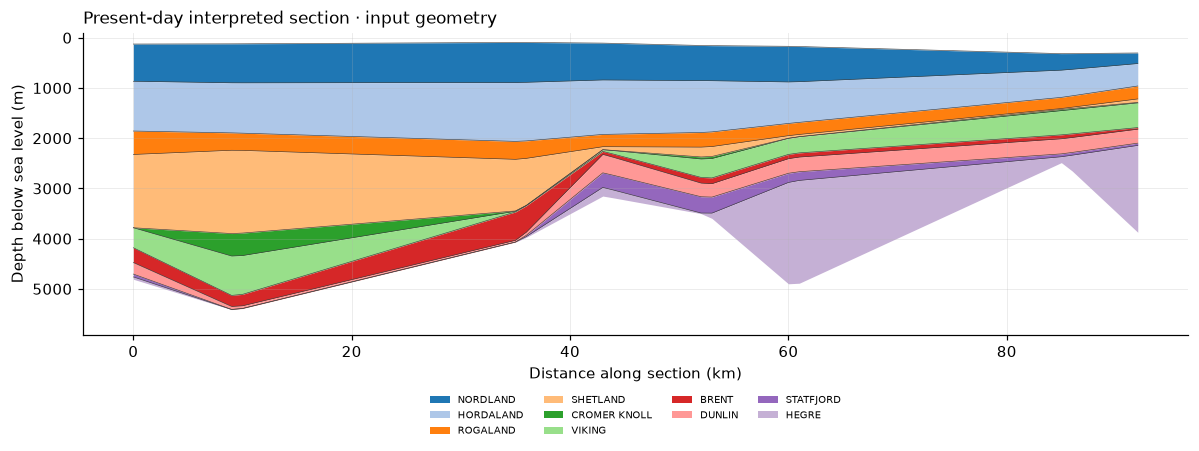

In [3]:
%matplotlib inline
from pybasinsubs.input_plots import stratigraphic_column, compaction_relations, interpreted_section
from IPython.display import display
import matplotlib.pyplot as plt
plt.ioff()
from pybasinsubs.flex2d import correlate
input_transect = correlate([r.column for r in R], x)
fig = interpreted_section(input_transect)
display(fig)
plt.close(fig)


## 2 · Compaction relations used

No measured well porosity logs are bundled; show the actual lithology parameters only.

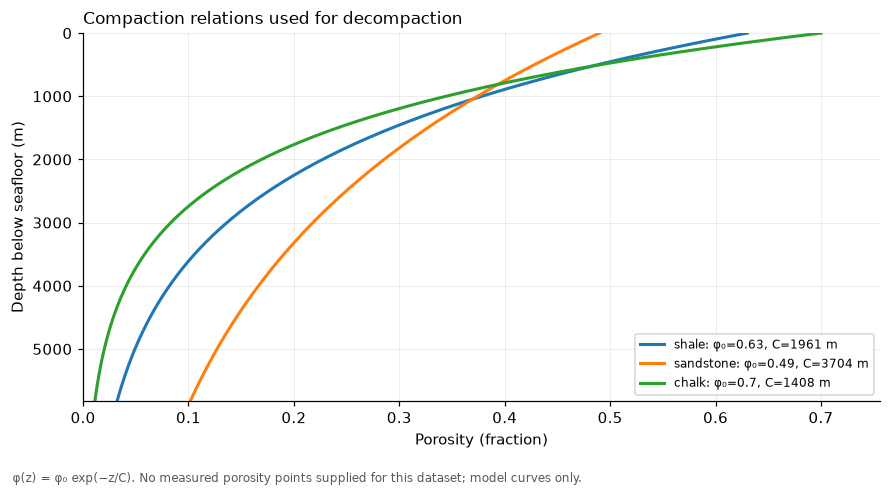

In [4]:
fig = compaction_relations(input_transect)
display(fig)
plt.close(fig)


## 3 · Restored well-transect sections through time

In [5]:
Te_vals, misfit, best, betas = fit_te(sec, rift_end_Ma=140.0)


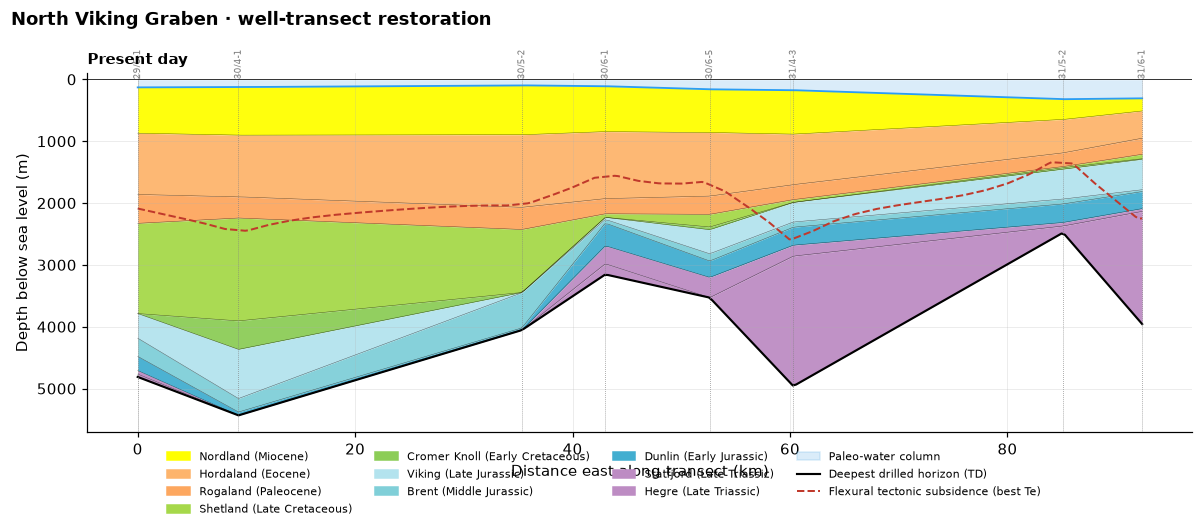

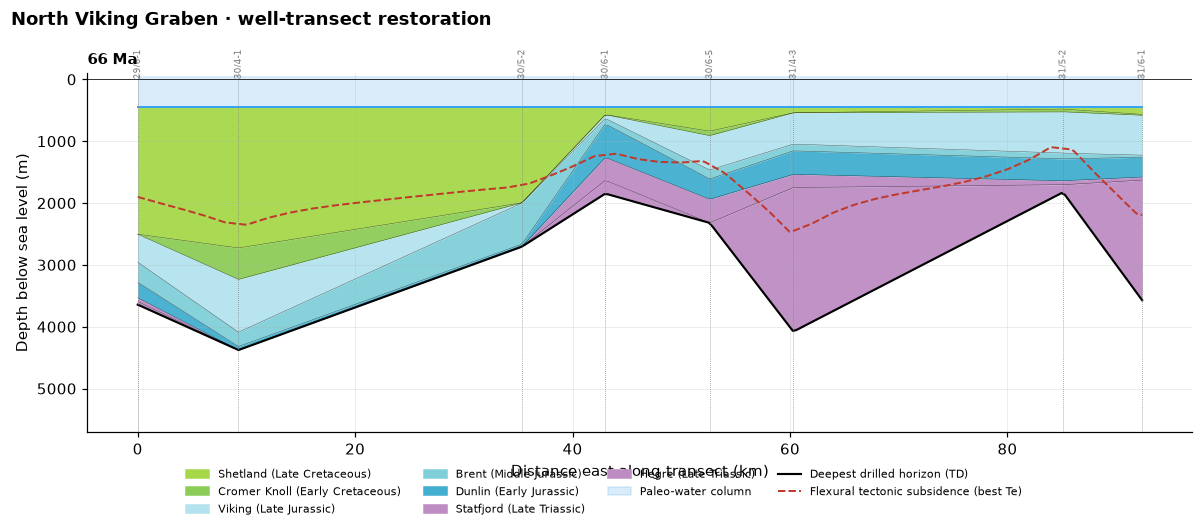

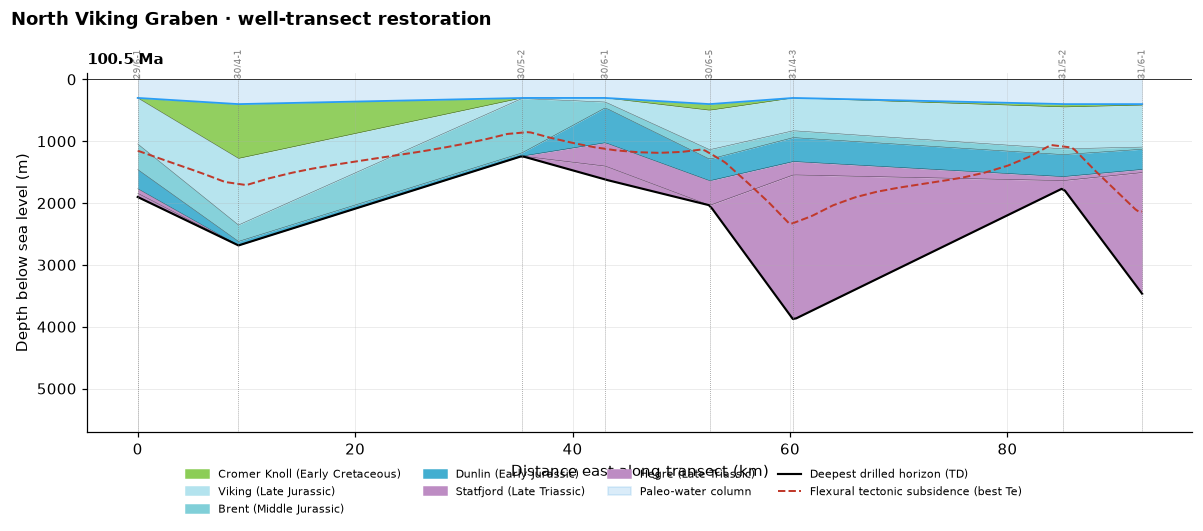

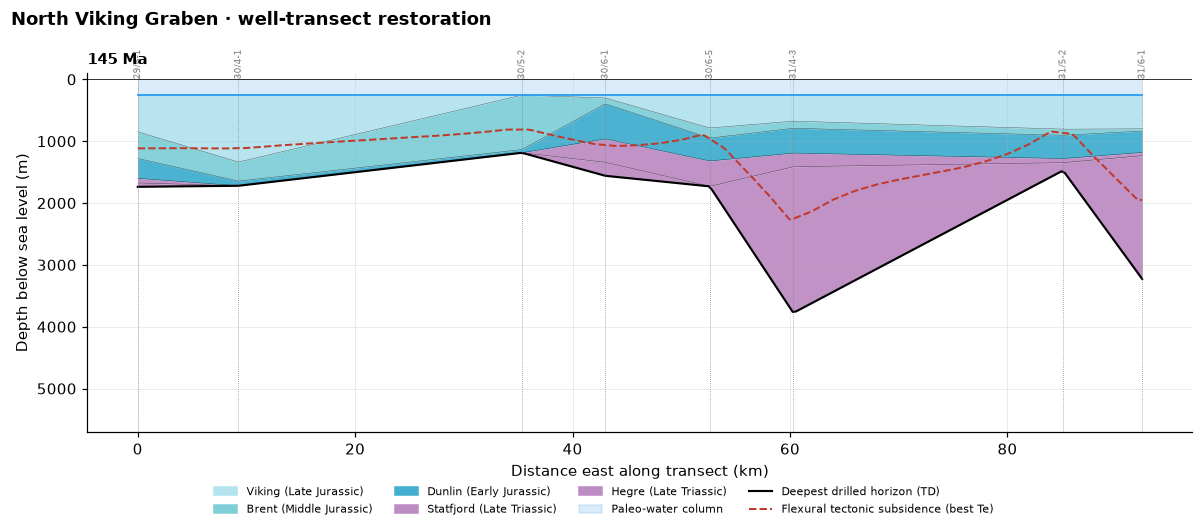

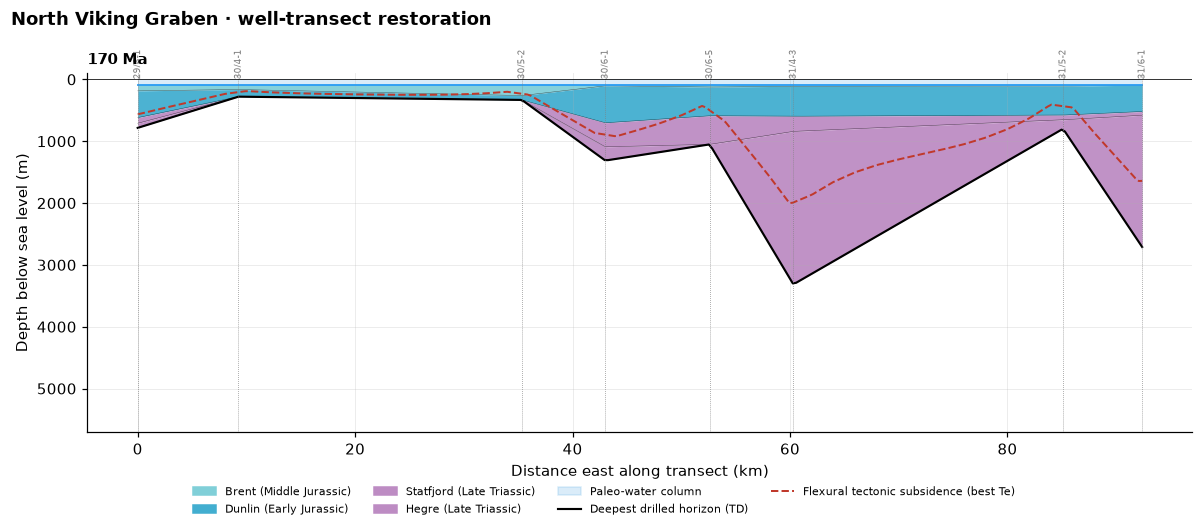

In [6]:
from pybasinsubs.flexure import section_geometry
from pybasinsubs.plotting import section_panel
snap = [0.0, 66.0, 100.5, 145.0, 170.0]
xx = np.linspace(x.min(), x.max(), 300)
secb = section_backstrip(R, x, [best], ages=snap)
geoms = [section_geometry(R, x, age, xx) for age in snap]
zmax = max(np.nanmax(g["base"]) for g in geoms) * 1.05
zmin = min(0., min(np.nanmin(g["top"]) for g in geoms)) - 100
for i, (age, geom) in enumerate(zip(snap, geoms)):
    flex = [(xx, np.interp(xx, secb["x"], secb["flex"][best][i]))]
    fig = section_panel([geom], [age], xw=x, wells=list(VG.well), flex_lines=flex,
                        figsize=(11, 4.5), title="North Viking Graben · well-transect restoration")
    # Shared physical depth limits for this sequence, one age per figure.
    fig.axes[0].set_ylim(zmax, zmin)
    display(fig); plt.close(fig)


One age per figure, with identical depth limits computed from all snapshots. These are correlated-well flexural/bathymetric sections, not inferred fault throws.

## 4 · Summary diagnostics

In [3]:
# FFT vs finite-difference check (constant Te)
xx = np.arange(0, 400e3, 2e3); q = np.where(abs(xx - 200e3) < 30e3, 1e7, 0.0)
from pybasinsubs.constants import RHO_M, RHO_W
wf = deflection_fft(q, 2e3, 10e3, RHO_M - RHO_W); wd = deflection_fd(q, 2e3, np.full_like(xx, 10e3), RHO_M - RHO_W)
print(f"max |FFT - FD| = {abs(wf - wd).max():.2f} m of {abs(wf).max():.0f} m")

max |FFT - FD| = 0.58 m of 333 m


saved image/nb7_flexure_profile_today.png


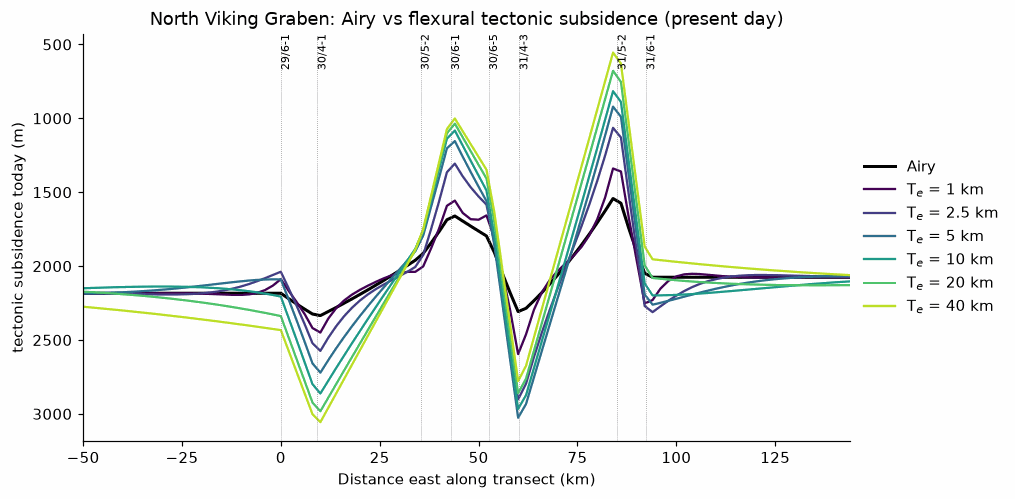

In [4]:
t0 = 0  # present day
fig, ax = plt.subplots(figsize=(9, 4.8))
xs = sec["x"] / 1e3
ax.plot(xs, sec["airy"][-1], "k-", lw=2, label="Airy")
for Te, c in zip(TE, plt.cm.viridis(np.linspace(0, .9, len(TE)))):
    ax.plot(xs, sec["flex"][Te][-1], color=c, label=f"T$_e$ = {Te/1e3:g} km")
for xi, w in zip(x / 1e3, VG.well): ax.axvline(xi, color="grey", lw=.5, ls=":"); ax.text(xi, ax.get_ylim()[0], w, rotation=90, fontsize=7, va="top")
ax.invert_yaxis(); ax.set_xlim(xs.min() + 100, xs.max() - 100)
ax.set_xlabel("Distance east along transect (km)"); ax.set_ylabel("tectonic subsidence today (m)")
ax.set_title("North Viking Graben: Airy vs flexural tectonic subsidence (present day)")
ax.legend(loc="center left", bbox_to_anchor=(1, .5), frameon=False)
save(fig, "nb7_flexure_profile_today.png"); plt.show()

**Reading.** Each curve is today's tectonic subsidence along the line of wells (dotted verticals; values between wells are linearly interpolated). Black is Airy, which removes the sediment load column by column. A stiffer plate (larger T_e) spreads the load sideways, so it does **not** remove local basement relief: footwall highs (30/6-1, 31/5-2) look shallower and the depocentres (30/4-1, 31/4-3) deeper than with Airy. With T_e ≈ 1 km the result is close to Airy. Profiles beyond the end wells are padded with the end-well values, so the edges are not meaningful.

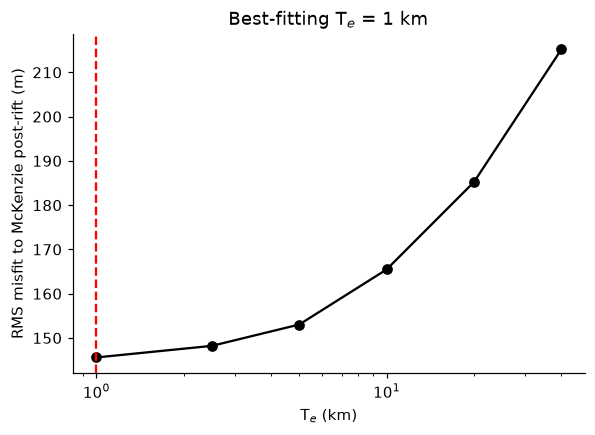

,well,beta_at_best_Te
0,29/6-1,1.30
1,30/4-1,1.46
2,30/5-2,1.41
3,30/6-1,1.12
4,30/6-5,1.19
5,31/4-3,1.07
6,31/5-2,1.09
7,31/6-1,1.06


In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(Te_vals / 1e3, misfit, "o-", color="k"); ax.axvline(best / 1e3, color="r", ls="--")
ax.set_xlabel("T$_e$ (km)"); ax.set_ylabel("RMS misfit to McKenzie post-rift (m)"); ax.set_xscale("log")
ax.set_title(f"Best-fitting T$_e$ = {best/1e3:g} km")
plt.show()
pd.DataFrame({"well": VG.well.values, "beta_at_best_Te": betas}).round(2)


**Reading.** The curve shows how well McKenzie post-rift cooling (one β per well) fits the flexural tectonic subsidence for each T_e. Lower is better. Here the misfit is lowest at the **smallest T_e**: the post-rift data from these 8 wells prefer a weak plate, i.e. close to Airy — consistent with published low T_e during rifting in the Viking Graben, but note that with only 8 wells over ~100 km and group-level stratigraphy, this is a weak constraint (misfit changes by only tens of metres).